# Домашнее задание 1

## 1. Сформулировать постановку задачу, которую хочется решать в рамках курса.

**Бизнес-задача:** Разработать механизм автоматизированного выявления фишинговых веб-сайтов на основании их характеристик для повышения эффективности обнаружения фишинга и сокращения объёма ручной проверки аналитиками ИБ, то есть помочь аналитику ИБ упростить проверку подозрительных веб-страниц и снижать число пропущенных фишинговых страниц.

**ML-задача:** Обучить модель на уже правильных ответах (Обучение с учителем), где модель будет выбирать один из двух возможных вариантов(классов). На основании 30 характеристик каждого сайта и заранее правильного ответа модель должна научиться определять является ли сайт фишинговым или легитимным (Вроде бинарная классификация называется)

**Набор данных:** UCI Phishing Websites: 11 055 строк и 30 признаков - data/Training Dataset.arff (оригинальный файл). Используемый DS - phishing_websites.csv. Для каждого сайта известен правильный ответ `Result` = `1` - легитимный сайт, `Result` = `-1` - фишинговый сайт.

## 2. Выбрать и обосновать метрику для измерения качества.

Термины для понимания моей логики:

- TP (True Positive) - сайт действительно фишинговый, и модель правильно определила его как фишинг.
- TN (True Negative) - сайт легитимный, и модель правильно определила его как легитимный.
- FP (False Positive) - легитимный сайт ошибочно определён как фишинг. Это ложное срабатывание.
- FN (False Negative) - фишинговый сайт ошибочно определён как легитимный. Это пропущенная угроза.

**Основная метрика:**

- `Полнота` - метрика, которая позволяет обнаруживать как можно большую долю действительно фишинговых сайтов, минимизируя кол-во пропущенных `Полнота = TP / (TP + FN)`.

Нам важно снизить процент пропущенных фишинговых страниц, чтобы снизить вектор атаки (фишинг, который приведет к взлому учетной записи и может привести к нарушению целостности, доступности и конфеденциальности)

**Доп. метрики:** 

Однако одной полноты недостаточно для полноценной оценки модели, поскольку она не учитывает ложные срабатывания. Поэтому дополнительно выбраны `Точность` и `Процент ошибок`.

- Процент ошибок - метрика, показывающая долю легитимных сайтов, которые модель ошибочно определила как фишинговые `Процент ошибок = FP / (FP + TN)`.

- Точность - метрика, показывающая, какая доля сайтов, определённых моделью как фишинговые, действительно является фишинговой `Точность = TP / (TP + FP)`. 

Аналитики ИБ будут тратить время на проверку легитимных сайтов. `Точность` позволяет оценивать достоверность предупреждений о фишинге, а `Процент ошибок` контролировать долю ошибочно классифицированных легитимных сайтов.

## 3. Провести EDA на своих данных

**Загрузка датасета**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/phishing_websites.csv")

print("Размер датасета:", df.shape)
df.head()

Размер датасета: (11055, 31)


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


**Проверка пропусков и дубликатов**

In [22]:
# Проверка пропущенных значений
print("Пропусков:", df.isna().sum().sum())

# Проверка полных дубликатов
print("Дубликатов:", df.duplicated().sum())

# Количество уникальных значений каждого столбца
display(df.nunique())

Пропусков: 0
Дубликатов: 5206


having_IP_Address              2
URL_Length                     3
Shortining_Service             2
having_At_Symbol               2
double_slash_redirecting       2
Prefix_Suffix                  2
having_Sub_Domain              3
SSLfinal_State                 3
Domain_registeration_length    2
Favicon                        2
port                           2
HTTPS_token                    2
Request_URL                    2
URL_of_Anchor                  3
Links_in_tags                  3
SFH                            3
Submitting_to_email            2
Abnormal_URL                   2
Redirect                       2
on_mouseover                   2
RightClick                     2
popUpWidnow                    2
Iframe                         2
age_of_domain                  2
DNSRecord                      2
web_traffic                    3
Page_Rank                      2
Google_Index                   2
Links_pointing_to_page         3
Statistical_report             2
Result    

In [24]:
feature_cols = df.columns.drop("Result").tolist()

# Совпадающие признаки, независимо от Result
print("Повторов признаковых векторов:",df[feature_cols].duplicated().sum())

# Одинаковые признаки с разными Result
conflicts = df.groupby(feature_cols)["Result"].nunique()

print("Противоречивых наборов признаков:",(conflicts > 1).sum())

Повторов признаковых векторов: 5270
Противоречивых наборов признаков: 64


**Преположение:**
- Дубликаты могут привести к завышенной оценке качества модели, поскольку она может запомнить повторяющиеся примеры вместо изучения закономерностей.
- Противоречивые метки затрудняют обучение, так как одинаковым характеристикам сайтов соответствуют разные правильные ответы.


**Вывод:**
Перед обучением необходимо проверить эти записи и исключить попадание одинаковых наборов признаков одновременно в обучающую и тестовую выборки.

**Решение:**
Либо не удалять повторы :), либо удалять, но потеряем чуть больше половины датасета (остаток 5721 запись)

**Распределение классов**

C:\Users\SystemX\AppData\Local\Temp\ipykernel_16456\3313600079.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Легитимные", "Фишинговые"],y=[counts[1], counts[-1]], palette=["green", "red"])


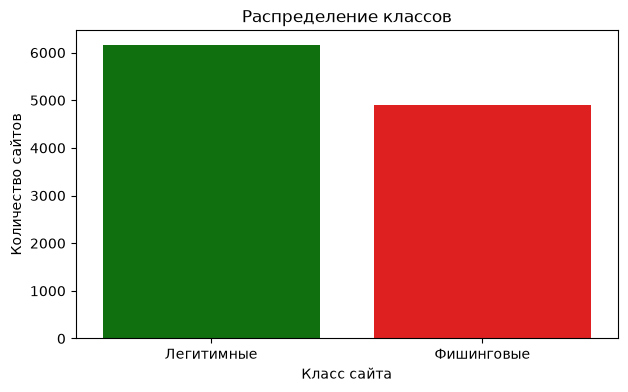

In [28]:
counts = df["Result"].value_counts()

plt.figure(figsize=(7, 4))

sns.barplot(x=["Легитимные", "Фишинговые"],y=[counts[1], counts[-1]], palette=["green", "red"])

plt.xlabel("Класс сайта")
plt.ylabel("Количество сайтов")
plt.title("Распределение классов")

plt.show()

**Анализ зависимости класса от признаков**

In [26]:
pd.crosstab(df["SSLfinal_State"],df["Result"],normalize="index").mul(100).round(2)
# создаёт таблицу сопряжённости


Result,-1,1
SSLfinal_State,,
-1,85.77,14.23
0,98.20,1.80
1,11.07,88.93


**Тепловая карта всех признаков**

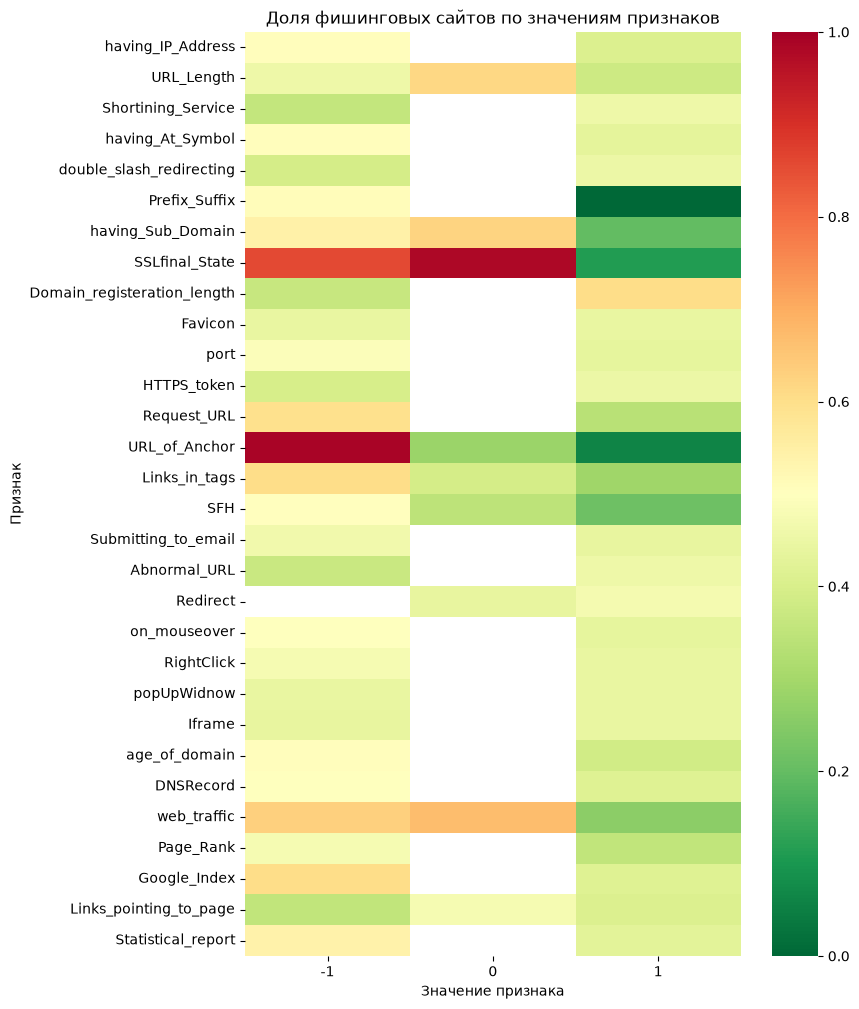

In [16]:
# Выбираем все признаки, кроме целевой переменной
feature_cols = df.columns.drop(
    ["Result", "label"], errors="ignore"
).tolist()

# Рассчитываем долю фишинга для каждого значения признака
rates = {
    col: df.groupby(col)["Result"].apply(
        lambda values: (values == -1).mean()
    )
    for col in feature_cols
}

# Преобразуем результат в таблицу
rate_table = pd.DataFrame(rates).T
rate_table = rate_table.reindex(columns=[-1, 0, 1])

# Строим тепловую карту
plt.figure(figsize=(8, 12))

sns.heatmap(
    rate_table,
    cmap="RdYlGn_r",
    vmin=0,
    vmax=1
)

plt.xlabel("Значение признака")
plt.ylabel("Признак")
plt.title("Доля фишинговых сайтов по значениям признаков")

plt.show()


- Красный - фишинг 
- Зеленый - легитимный

Особенно выделяются три признака:
1. SSLfinal_State - при значениях -1 и 0 доля фишинга очень высокая, а при 1 значительно ниже.
2. URL_of_Anchor - при значении -1 почти все сайты фишинговые, а при 1 их доля составляет лишь.
3. Prefix_Suffix - также заметно различие долей фишинга между категориями -1 и 1.

## Выводы по результатам EDA

В ходе разведочного анализа был изучен датасет Phishing Websites, содержащий 11 055 записей о веб-сайтах, 30 признаков и целевую переменную Result.

### Основные результаты:

- Пропущенные значения отсутствуют, поэтому дополнительное заполнение данных не требуется.

- Распределение классов относительно сбалансировано.

- Обнаружено 5 206 полных дубликатов, а также 64 уникальных набора признаков с противоречивыми метками классов.

- Признаки SSLfinal_State, URL_of_Anchor и Prefix_Suffix демонстрируют выраженную связь с принадлежностью сайта к фишинговому классу.